# **Details:**

**Name:** Vinit Jadhav

**PRN:** 202401040163

**Division:** A

**Roll No.:** 38


# **Title**

Practical Assignment 05 – Ensemble Learning and Performance Evaluation

# **Aim**

To implement and evaluate ensemble learning techniques—Stacking, AdaBoost, and Voting—and compare their performance with individual base machine learning classifiers using appropriate classification metrics.

# **Experiment Objectives**

- To understand the concept and purpose of ensemble learning.
- To load and preprocess a real-world classification dataset.
- To develop individual base classifiers for comparison.
- To implement a Stacking Classifier using a meta-classifier.
- To implement an AdaBoost ensemble using a selected base estimator.
- To implement a Voting Classifier using majority (hard) voting.
- To evaluate base and ensemble models using accuracy, precision, recall, F1-score, and log loss.
- To compare model performance and identify suitable use cases for each ensemble method.
- To discuss limitations and possible improvements.

# **Experiment Outcome**

- Explored a real-world binary classification dataset.
- Trained multiple individual classification algorithms.
- Combined base model predictions using Stacking, AdaBoost, and majority Voting.
- Evaluated all models using consistent test data and classification metrics.
- Compared the performance of individual and ensemble models.
- Examined confusion matrices and comparative visualizations.
- Identified the strengths, limitations, and suitable applications of ensemble methods.

# **Theory**

### 1. Ensemble Learning

Ensemble Learning is a Machine Learning approach that combines predictions from multiple models to produce a final prediction. The purpose is to improve predictive performance, stability, or generalization compared with using a single model.

### 2. Base Classifiers

Base classifiers are the individual models used by an ensemble. In this practical, Logistic Regression, Decision Tree, K-Nearest Neighbors (KNN), and Gaussian Naïve Bayes are used as base classifiers.

### 3. Stacking Ensemble

Stacking, also called Stacked Generalization, combines multiple base classifiers with a second-level model called a meta-classifier. The base classifiers generate predictions, and the meta-classifier learns how to combine those predictions.

**Advantages:** Can combine different model strengths and learn which predictions are useful.

**Limitations:** More computationally expensive and needs careful validation to avoid data leakage.

### 4. AdaBoost Ensemble

AdaBoost (Adaptive Boosting) combines a sequence of weak learners. Each new learner focuses more on observations that were incorrectly classified by earlier learners. The final prediction is based on a weighted combination of learner predictions.

**Advantages:** Can turn simple weak learners into a stronger classifier and is useful for structured classification tasks.

**Limitations:** Can be sensitive to noisy observations and outliers.

### 5. Voting Ensemble

A Voting Classifier combines predictions from multiple classifiers.

- **Hard Voting:** Each classifier votes for a class, and the class with the most votes is selected. This practical implements majority (hard) voting.
- **Soft Voting:** Averages predicted class probabilities and selects the class with the highest average probability. This is not the voting method required for the main implementation in this practical.

**Advantages:** Simple way to combine different classifiers and can improve robustness.

**Limitations:** Performance depends on the quality and diversity of the included classifiers.

### 6. Classification Evaluation Metrics

- **Accuracy:** Fraction of all predictions that are correct.
- **Precision:** Fraction of predicted positive cases that are actually positive.
- **Recall:** Fraction of actual positive cases correctly identified.
- **F1-score:** Harmonic mean of precision and recall.
- **Log Loss:** Evaluates the quality of predicted class probabilities. Lower values are better.

In this practical, malignant is treated as the positive class (label 0). This makes the meaning of precision, recall, and F1-score explicit.

### 7. Dataset Used

The Wisconsin Diagnostic Breast Cancer dataset from scikit-learn is used. It contains numerical measurements computed from digitized images of breast mass samples. The target classes are malignant and benign.

This dataset is used only for educational classification practice. The models are not medical diagnostic systems and must not be used to make healthcare decisions.

# **Problem Statement**

Develop individual base classifiers and ensemble models to classify observations in the Wisconsin Diagnostic Breast Cancer dataset as malignant or benign.

Implement the following:

1. Base classifiers: Logistic Regression, Decision Tree, KNN, and Gaussian Naïve Bayes.
2. Stacking Ensemble: Combine base classifiers using Logistic Regression as the meta-classifier.
3. AdaBoost Ensemble: Use a Decision Tree stump as the weak base estimator.
4. Voting Ensemble: Combine base classifiers using majority (hard) voting.

Compare the base and ensemble models using accuracy, precision, recall, F1-score, and log loss. Summarize the findings and discuss when each ensemble method is suitable.

# **1. Import Required Libraries**

Import the libraries required for data processing, visualization, classification, ensemble learning, and performance evaluation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


# **2. Load and Understand the Dataset**

Load the Wisconsin Diagnostic Breast Cancer dataset and inspect its dimensions, feature names, class labels, and first few records.

In [ ]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("Target labels:", list(dataset.target_names))
print("\nFirst five records:")
display(df.head())

print("\nDataset summary:")
display(df.describe().round(2))

Dataset shape: (569, 31)
Number of features: 30
Target labels: [np.str_('malignant'), np.str_('benign')]

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset summary:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,0.41,1.22,2.87,40.34,0.01,0.03,0.03,0.01,0.02,0.00,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08,0.63
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,0.28,0.55,2.02,45.49,0.00,0.02,0.03,0.01,0.01,0.00,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02,0.48
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,0.11,0.36,0.76,6.80,0.00,0.00,0.00,0.00,0.01,0.00,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06,0.00
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,0.23,0.83,1.61,17.85,0.01,0.01,0.02,0.01,0.02,0.00,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07,0.00
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,0.32,1.11,2.29,24.53,0.01,0.02,0.03,0.01,0.02,0.00,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08,1.00
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,0.48,1.47,3.36,45.19,0.01,0.03,0.04,0.01,0.02,0.00,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09,1.00
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,2.87,4.88,21.98,542.20,0.03,0.14,0.40,0.05,0.08,0.03,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21,1.00


# **3. Exploratory Data Analysis**

Check missing values and inspect the distribution of the two target classes. Class distribution helps understand whether the dataset is balanced.

Total missing values: 0

Class distribution:
malignant: 212
benign: 357


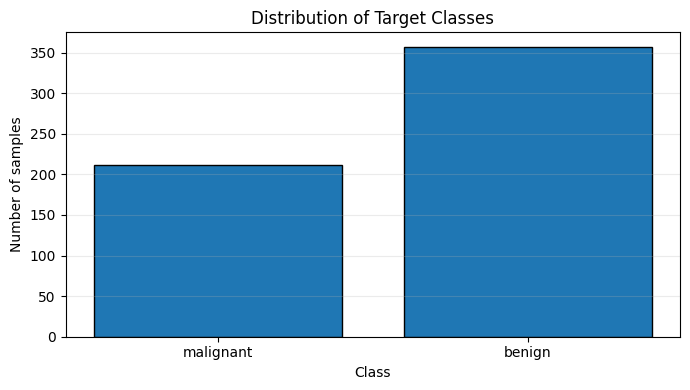

In [ ]:
print("Total missing values:", int(df.isnull().sum().sum()))

class_counts = y.value_counts().sort_index()
class_names = [dataset.target_names[i] for i in class_counts.index]

print("\nClass distribution:")
for name, count in zip(class_names, class_counts.values):
    print(f"{name}: {count}")

plt.figure(figsize=(7, 4))
plt.bar(class_names, class_counts.values, edgecolor="black")
plt.title("Distribution of Target Classes")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# **4. Data Preprocessing**

Split the dataset into training and testing sets using stratification. This preserves the approximate class proportions in both sets.

Scaling is important for Logistic Regression and KNN because they are affected by feature magnitudes. Pipelines ensure that the scaler is fitted only on training data. Decision Tree and Gaussian Naïve Bayes are used without scaling here.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training labels  :", y_train.shape)
print("Testing labels   :", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training features: (455, 30)
Testing features : (114, 30)
Training labels  : (455,)
Testing labels   : (114,)

Training class distribution:
target
0    170
1    285
Name: count, dtype: int64

Testing class distribution:
target
0    42
1    72
Name: count, dtype: int64


# **5. Develop Base Classifiers**

Create four individual classifiers. These models will be trained and evaluated independently and will also be used as components of the ensemble methods.

In [ ]:
base_estimators = [
    ("logistic", make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    )),
    ("tree", DecisionTreeClassifier(
        max_depth=4, random_state=RANDOM_STATE
    )),
    ("knn", make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )),
    ("naive_bayes", GaussianNB())
]

print("Base classifiers created:")
for name, estimator in base_estimators:
    print("-", name)

Base classifiers created:
- logistic
- tree
- knn
- naive_bayes


# **6. Implement Stacking Ensemble**

Stacking combines predictions from several base classifiers using a meta-classifier. Here, Logistic Regression is used as the final estimator.

The `StackingClassifier` uses cross-validation on the training data to generate out-of-fold predictions for training the meta-classifier. This helps prevent the meta-classifier from simply learning from predictions made on the same observations used to fit the base models.

In [ ]:
stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    cv=5,
    stack_method="auto",
    passthrough=False,
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)

print("Stacking ensemble trained successfully.")

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Stacking ensemble trained successfully.


# **7. Implement AdaBoost Ensemble**

AdaBoost trains weak learners sequentially. Each learner gives greater attention to observations that were misclassified by previous learners.

A Decision Tree with maximum depth 1 (a decision stump) is selected as the weak learner. The number of estimators is set to 100 and the learning rate is set to 0.5.

In [ ]:
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=RANDOM_STATE
)

adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)

adaboost_model.fit(X_train, y_train)

print("AdaBoost ensemble trained successfully.")
print("Number of estimators:", len(adaboost_model.estimators_))

AdaBoost ensemble trained successfully.
Number of estimators: 100


# **8. Implement Voting Ensemble (Majority Voting)**

The Voting Classifier combines the class predictions from Logistic Regression, Decision Tree, KNN, and Gaussian Naïve Bayes. With `voting="hard"`, the final class is selected by majority vote.

In [ ]:
voting_model = VotingClassifier(
    estimators=base_estimators,
    voting="hard",
    n_jobs=-1
)

voting_model.fit(X_train, y_train)

print("Majority voting ensemble trained successfully.")

Majority voting ensemble trained successfully.


# **9. Train and Evaluate Base and Ensemble Models**

Evaluate all four base classifiers and all three ensemble classifiers on the same held-out test set.

The positive class for precision, recall, and F1-score is malignant (label 0). For log loss, probability estimates are required. All selected models support `predict_proba`.

Hard (majority) Voting produces class labels rather than class probabilities in scikit-learn. Therefore, log loss is reported as N/A for this model; accuracy, precision, recall, and F1-score are still evaluated. Log loss is calculated for models that provide probability estimates.

In [ ]:
all_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=RANDOM_STATE
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Naive Bayes": GaussianNB(),
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Voting (Hard)": voting_model
}

results = []
predictions = {}
probabilities = {}

for name, model in all_models.items():
    # Fit only models that have not already been fitted as ensemble models.
    if name in ["Logistic Regression", "Decision Tree", "KNN", "Naive Bayes"]:
        model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test) if hasattr(model, "predict_proba") and name != "Voting (Hard)" else None

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=0, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, pos_label=0, zero_division=0),
        "Log Loss": log_loss(y_test, y_prob, labels=[0, 1]) if y_prob is not None else np.nan
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("Evaluation completed.")
print("Precision, recall and F1-score use malignant as the positive class (label 0).")
display(results_df.round(4))

Evaluation completed.
Precision, recall and F1-score use malignant as the positive class (label 0).


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.0777
1,Stacking,0.9737,0.9756,0.9524,0.9639,0.0929
2,Voting (Hard),0.9649,0.9524,0.9524,0.9524,NaN
3,KNN,0.9561,0.9512,0.9286,0.9398,0.4073
4,AdaBoost,0.9561,0.9744,0.9048,0.9383,0.3829
5,Decision Tree,0.9386,0.9070,0.9286,0.9176,1.6559
6,Naive Bayes,0.9386,0.9268,0.9048,0.9157,0.3713


# **10. Compare Base Models and Ensemble Models**

Separate the base classifiers and ensemble methods to compare their metrics. The comparison helps identify whether combining models improved performance on this particular test set.

In [ ]:
base_names = [
    "Logistic Regression", "Decision Tree", "KNN", "Naive Bayes"
]
ensemble_names = ["Stacking", "AdaBoost", "Voting (Hard)"]

base_results = results_df[results_df["Model"].isin(base_names)].copy()
ensemble_results = results_df[results_df["Model"].isin(ensemble_names)].copy()

print("Base classifier results:")
display(base_results.round(4))

print("Ensemble classifier results:")
display(ensemble_results.round(4))

Base classifier results:


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.0777
3,KNN,0.9561,0.9512,0.9286,0.9398,0.4073
5,Decision Tree,0.9386,0.9070,0.9286,0.9176,1.6559
6,Naive Bayes,0.9386,0.9268,0.9048,0.9157,0.3713


Ensemble classifier results:


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
1,Stacking,0.9737,0.9756,0.9524,0.9639,0.0929
2,Voting (Hard),0.9649,0.9524,0.9524,0.9524,NaN
4,AdaBoost,0.9561,0.9744,0.9048,0.9383,0.3829


# **11. Performance Visualization**

Compare accuracy, precision, recall, and F1-score for all models. Higher values are generally better for these metrics. Log loss is plotted separately because lower values are better.

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

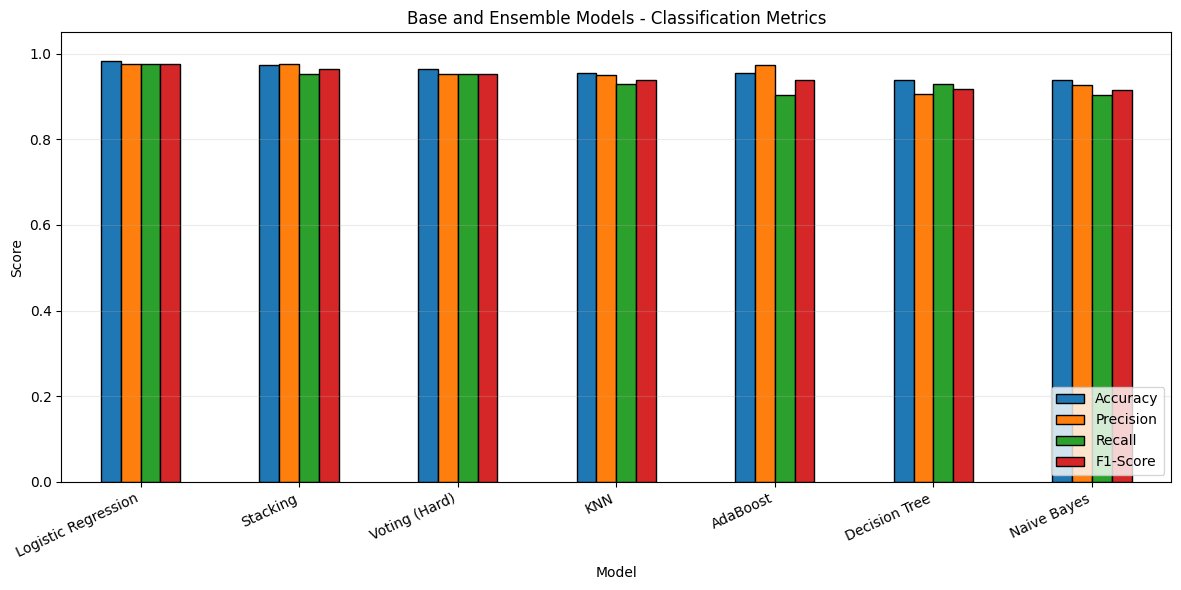

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

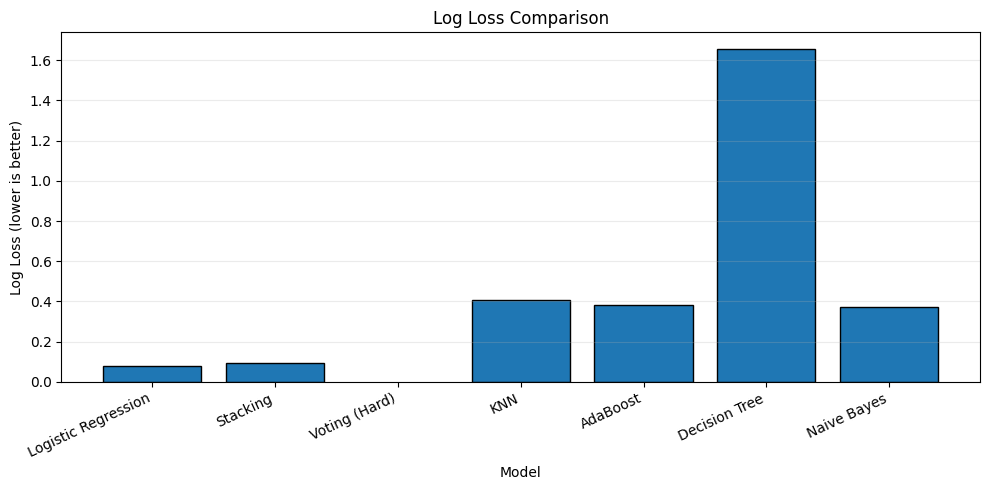

In [ ]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score"]

plot_df = results_df.set_index("Model")

plot_df[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    edgecolor="black"
)
plt.title("Base and Ensemble Models - Classification Metrics")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Log Loss"], edgecolor="black")
plt.title("Log Loss Comparison")
plt.xlabel("Model")
plt.ylabel("Log Loss (lower is better)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# **12. Confusion Matrix Analysis**

A confusion matrix shows the number of correct and incorrect predictions for each class.

- True Negative: Benign observations correctly classified as benign.
- False Positive: Benign observations incorrectly classified as malignant.
- False Negative: Malignant observations incorrectly classified as benign.
- True Positive: Malignant observations correctly classified as malignant.

The class order in the confusion matrices is [0, 1], which corresponds to [malignant, benign].

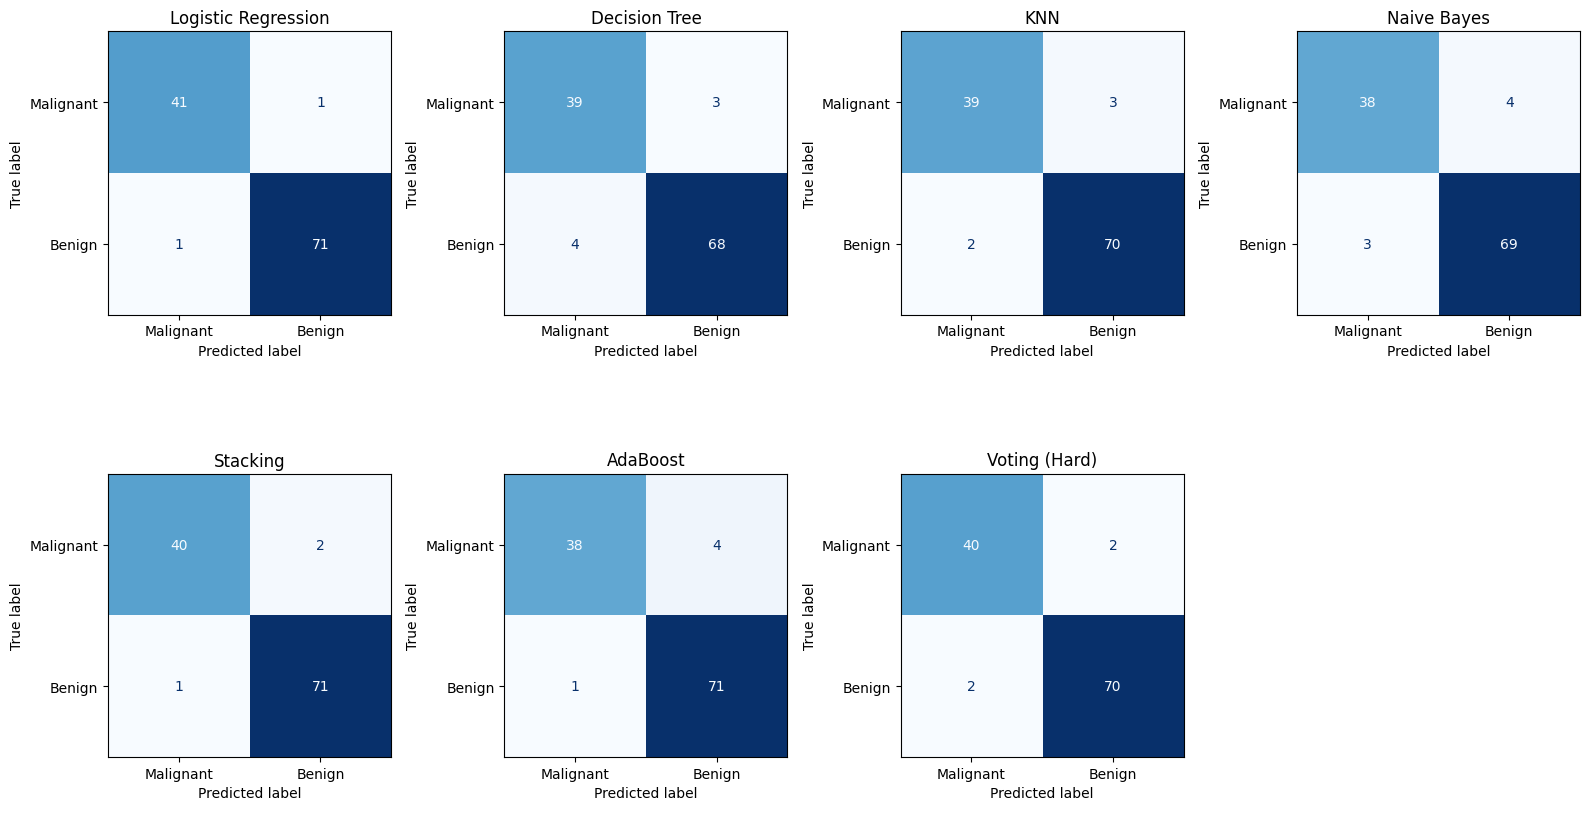

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

# Hide the unused eighth subplot.
for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# **13. Classification Reports**

Display class-wise precision, recall, F1-score, and support for each model. This helps identify whether a model performs differently for malignant and benign observations.

In [ ]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(f"Classification Report: {name}")
    print("=" * 70)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    ))

Classification Report: Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Classification Report: Decision Tree
              precision    recall  f1-score   support

   Malignant       0.91      0.93      0.92        42
      Benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Classification Report: KNN
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.

# **14. Identify the Best Model for Each Metric**

Different metrics can select different models. The following code identifies the model with the highest accuracy, precision, recall, and F1-score, and the lowest log loss.

In [ ]:
metric_winners = {
    "Highest Accuracy": results_df.loc[results_df["Accuracy"].idxmax(), "Model"],
    "Highest Malignant Precision": results_df.loc[results_df["Precision"].idxmax(), "Model"],
    "Highest Malignant Recall": results_df.loc[results_df["Recall"].idxmax(), "Model"],
    "Highest F1-Score": results_df.loc[results_df["F1-Score"].idxmax(), "Model"],
    "Lowest Log Loss": results_df.loc[results_df["Log Loss"].idxmin(), "Model"]
}

for metric, model_name in metric_winners.items():
    print(f"{metric}: {model_name}")

print("\nComplete performance table:")
display(results_df.round(4))

Highest Accuracy: Logistic Regression
Highest Malignant Precision: Logistic Regression
Highest Malignant Recall: Logistic Regression
Highest F1-Score: Logistic Regression
Lowest Log Loss: Logistic Regression

Complete performance table:


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.0777
1,Stacking,0.9737,0.9756,0.9524,0.9639,0.0929
2,Voting (Hard),0.9649,0.9524,0.9524,0.9524,NaN
3,KNN,0.9561,0.9512,0.9286,0.9398,0.4073
4,AdaBoost,0.9561,0.9744,0.9048,0.9383,0.3829
5,Decision Tree,0.9386,0.9070,0.9286,0.9176,1.6559
6,Naive Bayes,0.9386,0.9268,0.9048,0.9157,0.3713


# **15. Comparative Analysis of Ensemble Methods**

| Ensemble method | How it combines models | Main strengths | Limitations | Suitable situations |
|---|---|---|---|---|
| Stacking | Uses a meta-classifier trained on base-model predictions. | Can learn how to combine different model strengths. | More complex and computationally expensive; requires careful validation. | When diverse base models make complementary errors and there is enough data. |
| AdaBoost | Trains weak learners sequentially, emphasizing previously misclassified observations. | Can improve the performance of simple weak learners. | Sensitive to noisy labels and outliers; sequential training is less parallelizable. | Structured/tabular classification where weak learners perform better than chance. |
| Voting | Combines the class predictions of multiple classifiers using majority vote. | Simple, easy to implement, and can improve stability. | Does not learn an optimal combination; weak or correlated voters can reduce performance. | When several reasonably strong and diverse classifiers are available. |

### Base models versus ensemble models

- A base classifier is simpler and may be easier to interpret or deploy.
- Stacking is useful when different models contain complementary predictive information.
- AdaBoost is useful when a sequence of weak learners can correct earlier mistakes.
- Hard Voting is useful when several classifiers are individually reasonable and a simple consensus is desired.
- An ensemble is not guaranteed to outperform every individual classifier. The measured test metrics must guide the conclusion.

# **16. Result and Analysis**

After running the notebook, use the generated performance table, plots, and confusion matrices to write evidence-based observations.

- All four base classifiers and three ensemble classifiers were trained and evaluated using the same held-out test set.
- Accuracy measured overall correctness.
- Precision, recall, and F1-score focused on the malignant class (label 0).
- Log loss measured the quality of the predicted class probabilities.
- Stacking learned a combination of base-model predictions through a Logistic Regression meta-classifier.
- AdaBoost combined sequential weak learners, with each learner focusing more on observations misclassified earlier.
- Hard Voting selected the class receiving the majority of votes.
- The best ensemble method should be selected based on the actual results and application requirements, not on the assumption that ensembles always perform better.

**Important:** Do not insert assumed metric values. Use the numerical results generated by your executed notebook and explain any differences between base and ensemble models.

# **17. Potential Improvements and Further Research**

- Tune model hyperparameters using GridSearchCV or RandomizedSearchCV.
- Use repeated stratified cross-validation for more reliable performance estimates.
- Test other base classifiers and compare different combinations for Stacking and Voting.
- Investigate class weighting or resampling if class imbalance affects the results.
- Calibrate predicted probabilities before relying on log loss or probability thresholds.
- Evaluate performance on an independent external dataset.
- Study feature selection and dimensionality reduction.
- Compare additional ensemble techniques such as Random Forest and Gradient Boosting.
- Examine fairness, privacy, and the consequences of false positive and false negative predictions.

# **18. Ethical Considerations and Limitations**

- The dataset is intended for educational and research use; it may not represent all patient populations.
- The models must not be used to diagnose patients or replace qualified medical professionals.
- Dataset bias can lead to different error rates across population groups.
- False negative predictions may be harmful in a medical screening context.
- False positive predictions can cause unnecessary concern and further testing.
- Medical data must be handled with privacy, security, and consent safeguards.
- Real-world use would require external validation, fairness testing, calibration, domain-expert review, and regulatory approval.
- Performance on one train-test split does not guarantee performance on future or unseen data.

# **Conclusion**

In this practical, ensemble learning techniques were implemented and evaluated using the Wisconsin Diagnostic Breast Cancer dataset. Four base classifiers—Logistic Regression, Decision Tree, KNN, and Gaussian Naïve Bayes—were developed and compared with three ensemble methods: Stacking, AdaBoost, and majority Voting.

The models were evaluated using accuracy, precision, recall, F1-score, and log loss. Confusion matrices, classification reports, and visualizations were used to understand their performance.

The experiment demonstrated that Stacking learns how to combine base-model predictions, AdaBoost builds a sequence of weak learners, and Voting combines model decisions through majority voting. The most suitable approach depends on the dataset, model diversity, computational requirements, and the cost of classification errors.

Thus, the practical provided an understanding of ensemble learning and comparative performance evaluation.